# Part 1: What are Flipkart customers really saying?
**Data:** 40K real Flipkart product reviews across 205 products (Hugging Face Hub: `ml-hub/flipkart-reviews`), loaded at run time and not redistributed.

**Models (all from 🤗 Hugging Face, CPU only):**
| Task | Model | Training needed |
|---|---|---|
| Sentiment | `cardiffnlp/twitter-roberta-base-sentiment-latest` | none (pretrained) |
| Complaint aspects | `MoritzLaurer/deberta-v3-base-zeroshot-v2.0` (zero-shot NLI) | none |
| Topic discovery | `sentence-transformers/all-MiniLM-L6-v2` embeddings + UMAP + k-means + c-TF-IDF | none |

Slow transformer steps are cached by `src/precompute.py`; this notebook reads the cache.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display
from reviews import *
import charts
df = load_reviews()
print(f'{len(df):,} reviews · {df["product"].nunique()} products · median {df.n_words.median():.0f} words')
display(df.rating.value_counts(normalize=True).sort_index().round(3).to_frame('share'))
df.category.value_counts().head(10)

30,011 reviews · 205 products · median 5 words


,share
rating,
1,0.140
2,0.039
3,0.083
4,0.192
5,0.547


category
Audio                       6224
Beauty & fragrance          2673
Kettles & cookers           2572
Sports & fitness            2485
Cameras                     1836
Air coolers                 1632
Kitchen chimneys            1595
Food processors & mixers    1555
Storage                     1540
Stationery                  1528
Name: count, dtype: int64

## 1. Sentiment: a pretrained transformer vs a model trained on star labels
Stratified sample of 1,200 reviews per star rating (≥3 words). The supervised baseline (TF-IDF + logistic regression) is trained on all *other* (de-duplicated) reviews using stars as labels.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
sample = pd.read_parquet(CACHE / 'review_sample.parquet')
sent = transformer_sentiment(sample.text)
train = df[~df.text.isin(sample.text)]
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
clf = LogisticRegression(max_iter=2000, class_weight='balanced').fit(vec.fit_transform(train.text), train.star_sentiment)
base_pred = clf.predict(vec.transform(sample.text))
comp = pd.DataFrame({'macro_F1_vs_star_label': [f1_score(sample.star_sentiment, base_pred, average='macro'),
                                                f1_score(sample.star_sentiment, sent.pred, average='macro')]},
                    index=[f'TF-IDF + LogReg (trained on {len(train):,} star-labelled reviews)', 'RoBERTa sentiment (zero training)'])
comp.round(3)

,macro_F1_vs_star_label
"TF-IDF + LogReg (trained on 23,029 star-labelled reviews)",0.643
RoBERTa sentiment (zero training),0.651


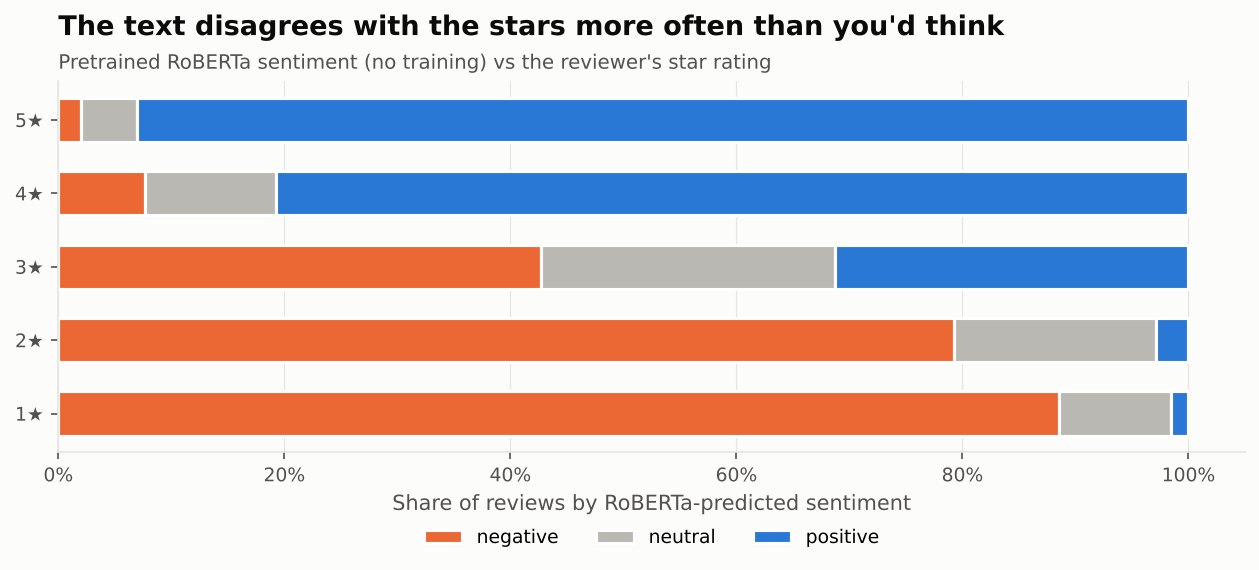

In [3]:
d = sample.join(sent)
charts.sentiment_by_rating(d)
display(Image('../images/sentiment_by_rating.png'))

### Hidden complaints: 4–5★ reviews whose *text* is clearly negative
These are invisible to any star-based dashboard.

In [4]:
mm = mismatches(sample, sent)
print(mm.kind.value_counts().to_string())
pd.set_option('display.max_colwidth', 140)
mm[mm.kind.str.startswith('4-5')].sort_values('negative', ascending=False).head(8)[['rating', 'text', 'negative']]

kind
1-2★ but positive text    18
4-5★ but negative text    15


,rating,text,negative
5247,5,very worst purchase i have ever purchased cheap product and awkward service n customer support waste of money,0.948403
3714,4,its a worst experiencenot bye thisits a new product but not working,0.948111
4554,5,quality not good once you buy you cannot return this i am really disappointed how many times i returned but they said sorry i cannot ret...,0.937806
5210,5,very soundless product and low price other company,0.930041
5526,5,very very very bad perfume,0.924469
4342,4,product is goodbut the worst experience with delivery boys behavior everthe box was half opened how can you deliver a half open box deli...,0.922077
4943,5,good but pipe r so bad quality,0.894803
4382,4,product is good by this seller but delivery of flipkart is like worst ever i have given two orders in this month as they displayed 34 da...,0.892711


## 2. Zero-shot aspect tagging of complaints
300 one- and two-star reviews (≥6 words), 9 business aspects, multi-label. No labelled data needed: an NLI model scores each single-concept hypothesis (e.g. *"The delivery was late."*) against the review.

52% of complaints match none of the 9 aspects


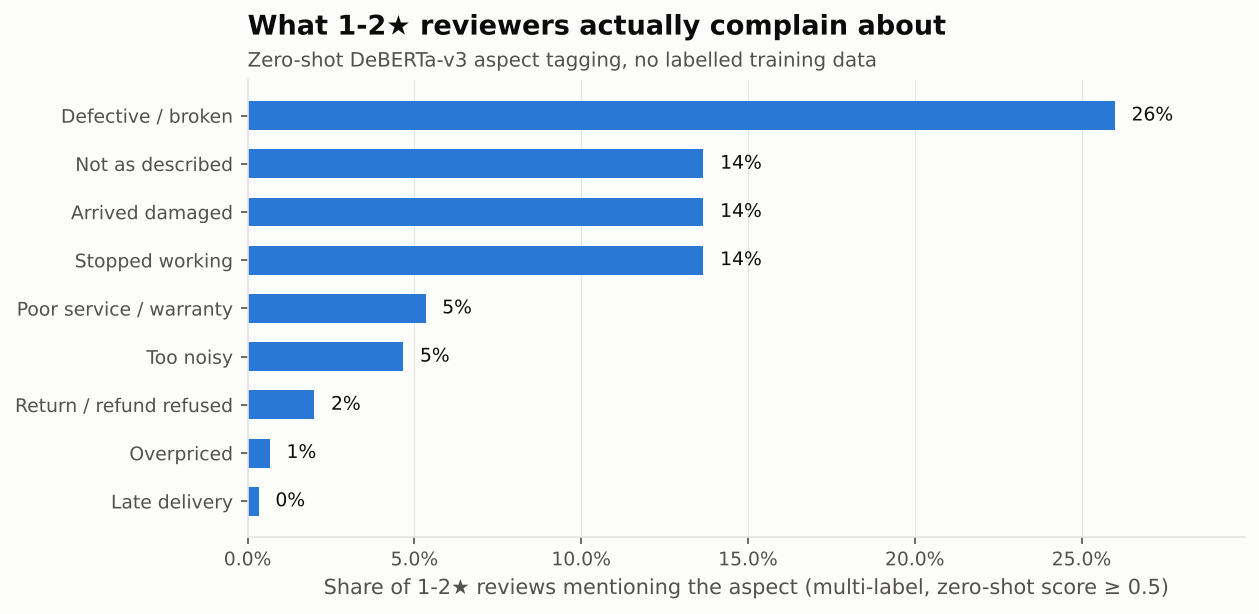

In [5]:
neg = pd.read_parquet(CACHE / 'negative_sample.parquet')
asp = zero_shot_aspects(neg.text)
flags = asp >= 0.5
rates = 100 * flags.mean()
charts.aspect_chart(rates)
print(f'{(flags.sum(1) == 0).mean():.0%} of complaints match none of the 9 aspects')
display(Image('../images/complaint_aspects.png'))

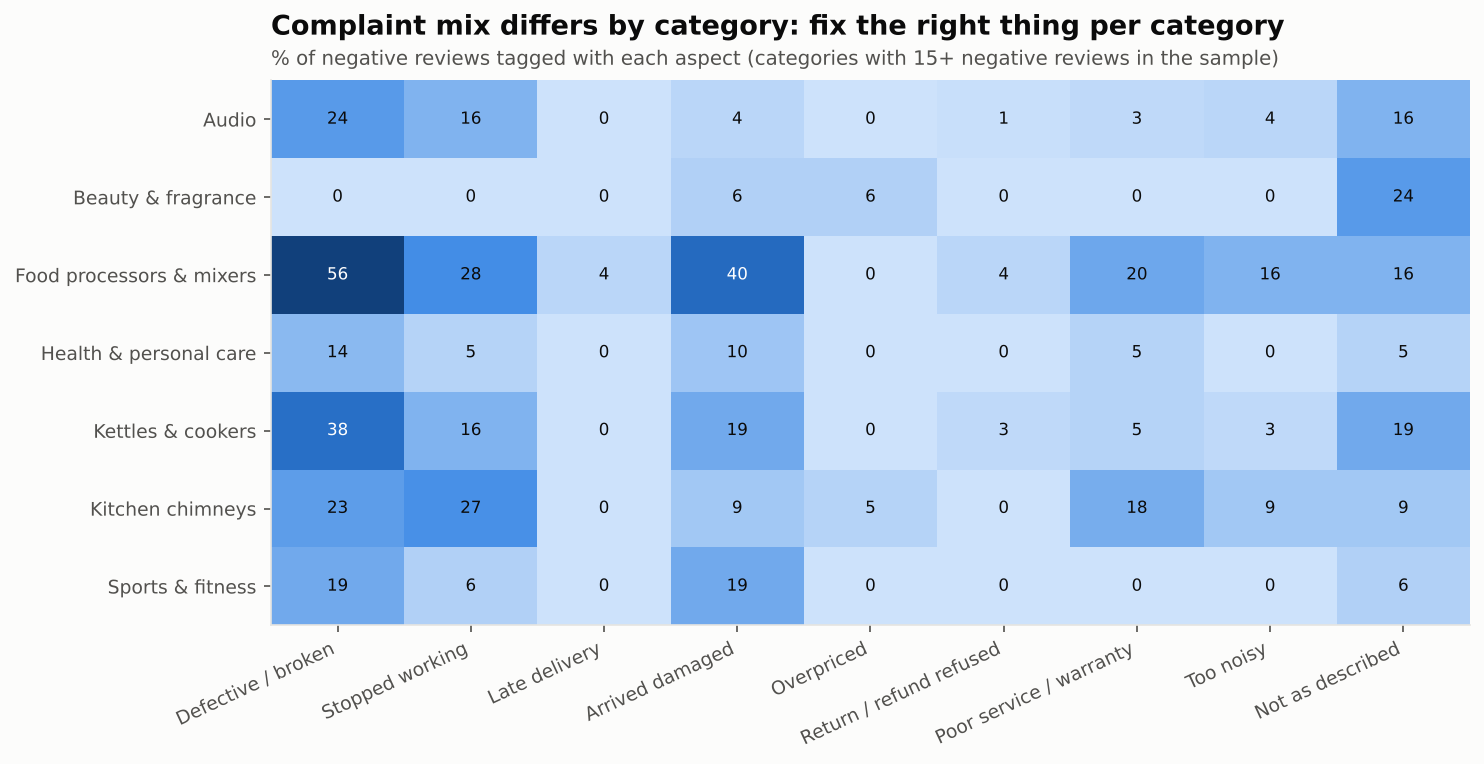

In [6]:
cat = neg.join(flags).groupby('category')
m = (100 * cat[list(flags.columns)].mean()).loc[cat.size()[lambda s: s >= 15].index]
charts.aspect_heatmap(m.round(0))
m.round(0).to_csv('../reports/aspects_by_category.csv')
display(Image('../images/aspects_by_category.png'))

In [7]:
# the most confident example for each aspect (sanity check of the zero-shot model)
pd.DataFrame({a: [neg.text.loc[asp[a].idxmax()][:160], round(asp[a].max(), 3)] for a in asp.columns}, index=['example', 'score']).T

,example,score
Defective / broken,the product quality was so bad i have received it in june and its main machine part through which grinder and mixer attaches with the ma...,0.993
Stopped working,worst product everit stopped working after few days of purchasing,0.998
Late delivery,late delivery took 13 days to deliver this product it was a gift to my mom and sadly couldnt gift it cause of poor delivery,0.994
Arrived damaged,worst returnrefund service this time from flipkart i received the delivery on time from flipkart but the product was damaged on arrival ...,0.998
Overpriced,the chimney was good but the installation guy was pathetic i had to manually install the pipeps i got cheated as the installation guy ov...,0.688
Return / refund refused,worst product never buy this product flipkart will never return your money its a cheap quality plastic product that worth only1000bucks,0.969
Poor service / warranty,product is ok but service of bajaj products are done by very irresponsible agencies have registered for service after product got busted...,0.98
Too noisy,worst product ever too much sound and cant even grind 100 gms of any dr y spices please dont buy this product,0.991
Not as described,worst product i got totally different product as compared to product shown in picture and its not in working condition i thought its not...,0.994


## 3. Topic discovery with sentence embeddings
All 1–3★ reviews with ≥5 words → MiniLM embeddings → k-means (k = 12) → UMAP for the 2-D map → **c-TF-IDF** (the BERTopic idea) to name each topic.

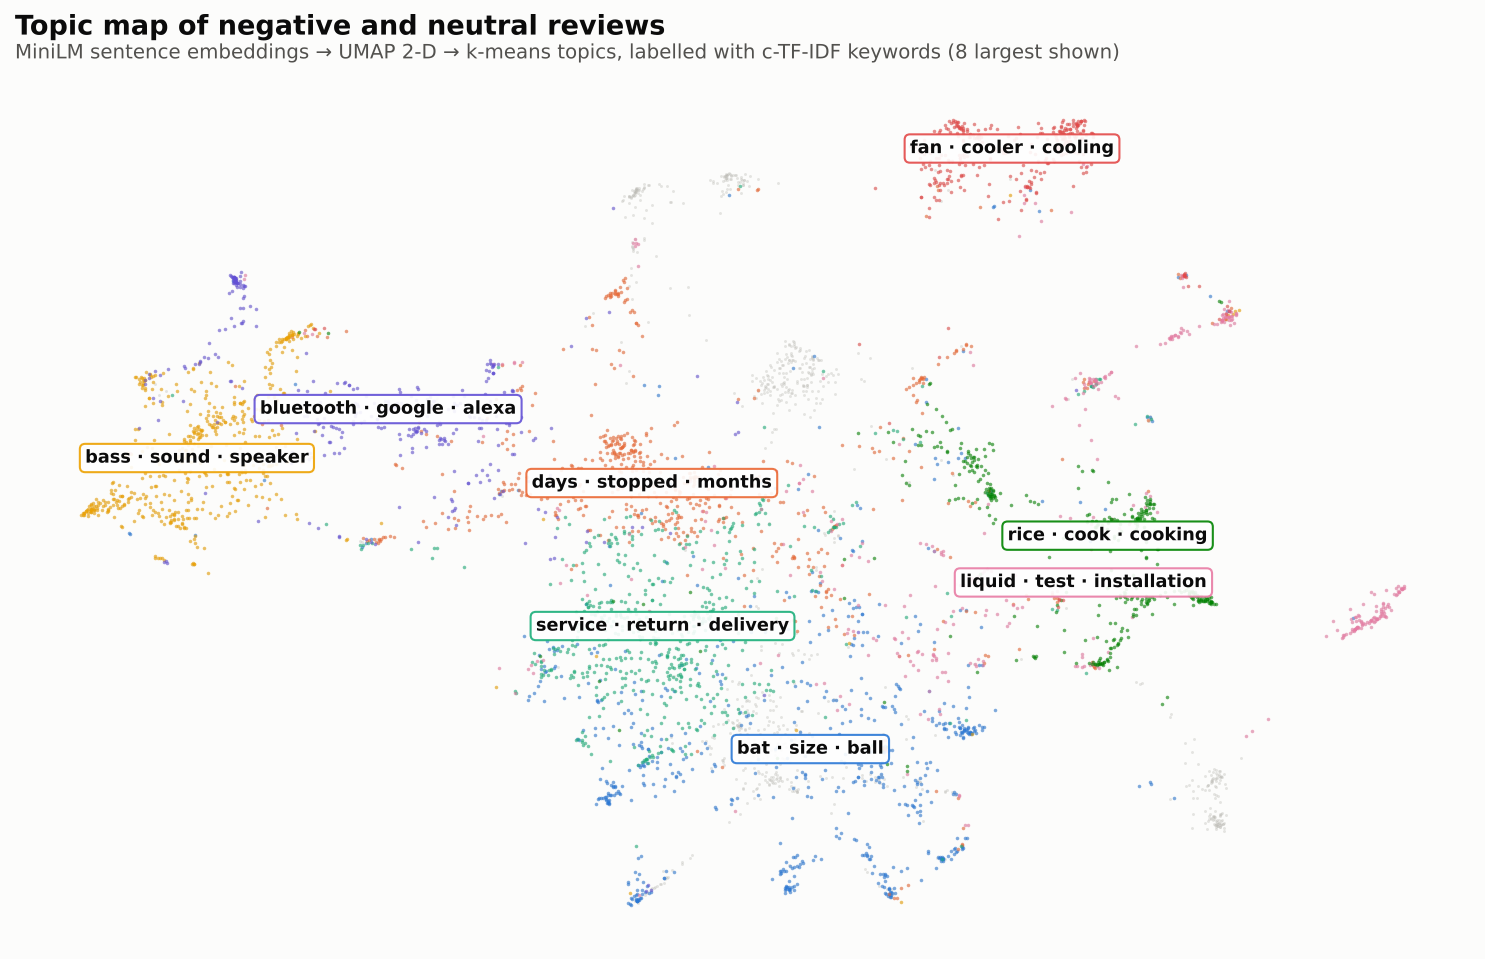

,reviews,avg_rating,keywords,example
topic,,,,
5,672,1.98,"bat, size, ball, small, skating, shoe",after discount rs 7200 price is okquality is okdelivery as on time okmotor speed 1200 rpm okpump okcolour is o
0,612,1.36,"days, stopped, months, month, properly, disk",received dalay 10 days cooler is ok when i was reveived switch damaged
10,586,1.43,"service, return, delivery, price, time, service pathetic",very bad product its water tank is not sufficient for a day tank empty in 4 hours and not open easily for clea
3,533,1.93,"bass, sound, speaker, music, mic, sound bass",size is too big useful for functions only making too much sound
6,418,1.56,"liquid, test, installation, kits, kit, pipe",this is my review after using this product for a week1air throw is good2produce less noise3good product at rea
1,391,1.91,"rice, cook, cooking, food, utensils, jar",the size and capacity is definitely big but i couldnt find how to open this for cleaning
7,343,1.74,"bluetooth, google, alexa, wifi, music, speaker",this is a very important review about this product1 the product dont work with wire2 the controls may not work
2,328,1.94,"fan, cooler, cooling, air, fan speed, speed",very bad product its a only a fan
11,323,1.62,"camera, low, material, build, price, size",the quality is good but the power of air is decent


In [8]:
from sklearn.cluster import KMeans
import umap
topic = pd.read_parquet(CACHE / 'topic_docs.parquet')
E = embed(topic.text)
labels = KMeans(12, n_init=10, random_state=0).fit_predict(E)
kw = class_tfidf_keywords(topic.text, labels)
names = {k: ' · '.join(v[:3]) for k, v in kw.items()}
xy = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=0).fit_transform(E)
charts.topic_map(xy, labels, names)
summary = (topic.assign(topic=labels).groupby('topic').agg(reviews=('text', 'size'), avg_rating=('rating', 'mean'))
           .assign(keywords=lambda t: t.index.map(lambda k: ', '.join(kw[k])), example=lambda t: t.index.map(lambda k: topic.text[labels == k].iloc[0][:110]))
           .sort_values('reviews', ascending=False))
summary.round(2).to_csv('../reports/topics.csv')
display(Image('../images/topic_map.png'))
summary.round(2)

## Takeaways
See the README. In short: star ratings hide complaints, a zero-training transformer beats a supervised TF-IDF baseline on sentiment, and zero-shot aspects turn 300 complaints into a ranked fix-list per category without labelling a single review.